 # $$\textbf{CUADRATURA ADAPTABLE PARA INTEGRALES}$$

Ya habíamos planteado el problema de las integrales numéricas desde antes, pero se propusieron soluciones prácticas (por el momento); ahora viene un nuevo problema. Supongamos que queremos saber el área bajo la curva de alguna $f(x)$ en el intervalo de $0$ a $3$ en especial, con una presición de al menos 5 decimales de la función siguiente

$$f(x)=\cos(x^{5/2})+\sqrt{x}$$

Se expone a continuación su gráfica


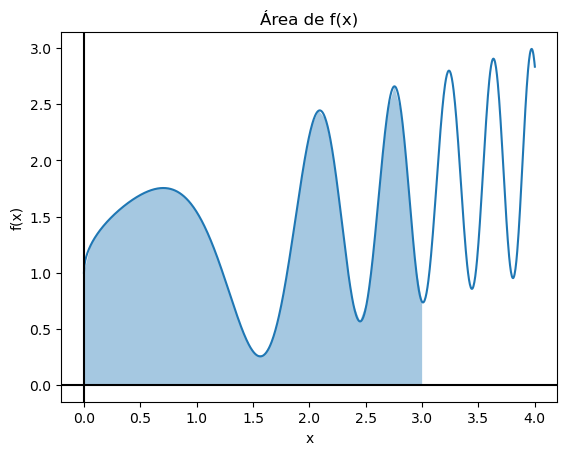

In [13]:
import numpy as np
import matplotlib.pyplot as plt #abrimos las librerias para funciones y gráficas
def ej(x): #así definiremos nuestra funcion ejemplo f(x)
    return np.cos(x**(5/2))+np.sqrt(x) #nos devolverá nuestra funcion ejemplo f(x)
    
xx=np.linspace(0,4,1000) #genera una reticula o una partición
plt.plot(xx,ej(xx)) #dibuja la gráfica de nuestra función ejemplo
plt.xlabel('x') #un pequeño letrero que indica los valores de x
plt.ylabel('f(x)') #un pequeño letrero que indica los valores de f(x)
plt.title('Área de f(x)') #xncabezado de la gráfica
plt.axhline(y=0, color = 'black') #pinta un eje X
plt.axvline(x=0, color = 'black') #pinta un eje Y
a_I=np.linspace(0,3) #es importante esto, funciona como indicador para el área que se quiere sombrear de la integral
plt.fill_between(a_I, ej(a_I), 0, alpha=0.4) #colorea el area bajo la curva de f(x) de 0 a 3


Como podemos ver, existen espacios irregulares entre oscilaciónes, y esto puede generarnos problemas al usar nuestros métodos numéricos expuestos anteriormente, ¿y esto por qué? bueno, el problema surge por la manera en la que que desarrolla nuestras fórmulas.

Nosotros hemos propuesto las fórmulas anteriores para cualquier intervalo $[a,b]$ con la particularidad de que se divide en $n$ partes iguales; aquí el inconveniente. Si seguimos usando estos artefactos para cualquier función $f(x)$ sin antes haber siquiera discriminado un poco la forma en la que se comporta esta el resultado nos va a dar lejos de algo óptimo, e incluso nos daría un resultado erroneo.

Pero entonces, ¿qué podemos hacer? la respuesta es más o menos intuitiva. Supongamos que tenemos a $f(x)$, función al menos de clase $C^4$, y queremos averiguar el área bajo la curva (sea positiva o negativa) de ella, inherentemente podemos usar la regla de Simpson ya que es lo mejor que tenemos (y lo más facil) para aplicar a nuestro problema. Recordemos nuestra regla de Simpson

$$\int_{x_0}^{x_2} f(x)\,dx=\frac{h}{3}[f(x_0)+4f(x_1)+f(x_2)]-\frac{h^5}{90}f^{IV}(\xi);  x_0=a, x_2=b, x_1=\frac{a+b}{2}, \xi\in[x_0,x_2]$$

Recordemos cuál es nuestro problema; supongamos que sabemos que $f(x)$ tiene algunas variaciones abruptas y leves en el esbozo de su curva, en un primer intento de calcular el area bajo su curva determinamos que el resultado no nos convence tanto, ¿podemos adaptar una nueva manera de integración a nuestro intervalo deseado sin desperdiciar nuestras fórmulas anteriores? la respuesta es si. Nuestro problema va a ser saber integrar las áreas con comportamiento brusco y leve por partes, ¿podemos adaptar a nuestra regla a integrar las áreas de distinto comportamiento por intervalos separados?. Ahora si, reenombraremos algunas cosas en nuestra fórmula de Simpson; tenemos que integrar el intervalo de $[a,b]$ de $f(x)$, con un paso $h=(b-a)/2$, tomando en cuenta una tolerancia de $\varepsilon>0$, nuestra fórmula se convierte en

$$\int_{a}^{b} f(x)\,dx=S(a,b)-\frac{h^5}{90}f^{IV}(\xi);$$ con$$S(a, b)=\frac{h}{3}[f(a)+4f(a+h)+f(b)]$$ para algunos  $$\xi\in[a,b]$$

Ocuparemos algo de astucia en esto. Si aplicamos a lo anterior la regla compuesta de Simpson con $n=4$ tenemos que

$$\int_{a}^{b} f(x)\,dx=S(a,\frac{a+b}{2})+S(\frac{a+b}{2},b)-\frac{1}{16}·\frac{h^5}{90}f^{IV}(\tilde{\xi});$$ con$$S(a,\frac{a+b}{2})=\frac{h}{6}[f(a)+4f(a+\frac{h}{2})+f(a+h)]$$
$$S(\frac{a+b}{2},b)=\frac{h}{6}[f(a+h)+4f(a+\frac{3}{2}h)+f(b)]$$


Puede que lo que viene suene repentino, pero es necesario que supongamos que $\xi\approx\tilde{\xi}$, tendríamos que "igualar" la primera ecuacion obtenida de $S(a,b)$ y $S(a,\frac{a+b}{2})+S(\frac{a+b}{2},b)$. Eso nos daría
$$S(a,\frac{a+b}{2})+S(\frac{a+b}{2},b)-\frac{1}{16}·\frac{h^5}{90}f^{IV}(\tilde{\xi})\approx S(a,b)-\frac{h^5}{90}f^{IV}(\xi)$$

luego

$$\frac{1}{16}\frac{h^5}{90}f^{IV}(\tilde{\xi})\approx \frac{1}{15}[S(a,b)-S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)]$$

y esto nos quiere decir que nuestro error es quince veces el error de las aproximaciones, entonces quiere decir que

$$[\int_{a}^{b} f(x)\,dx-S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)]\approx \frac{1}{15}[S(a,b)-S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)]$$

o en otras palabras, para $\int_{a}^{b} f(x)\,dx$ nos ha aproximado 15 veces mejor $S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)$ que $S(a,b)$, es decir que tenemos para las dos fórmulas de cuadratura que

$$\left|S(a,b)-S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)\right|\approx 15\varepsilon$$
y
$$\left|\int_{a}^{b} f(x)\,dx-S(a,\frac{a+b}{2})-S(\frac{a+b}{2},b)\right|\approx \varepsilon$$

que concuerda con lo que hemos dicho antes. Ha sido exhaustivo hallar estos valores, pero todo viene de suponer que los dos errores para cada cuadratura son iguales. Y con eso podemos adaptar cualquier intervalo $[a, b]$ dependiendo la forma de la curva,si tiene cambios leves o cambios fuertes. Se mostrará el código base que nos servirá como ayuda para la explicación de nuestro ejemplo.

$$\textbf{Código para la cuadratura adaptable}$$

In [5]:
import numpy as np #redundantemente llamamos a la libreria solo para no perderla de vista

def c_a(f, a, b, T, N):#Asi llamaremos a nuestra funcion de cuadratura adaptable
    
    APP=0
    Eval=3
    s_div=0
 #Hemos declarado unas variables para su uso posterior en el código
    h=(b-a)/2
    FA=f(a)
    FC=f(a+h)
    FB=f(b)
    S=h*(FA+4*FB+FC)/3
    #Lo anterior fue para calcular la regla de Simpson en un intervalo [a,b]
    pila=[(a,h,T,S,1,FA,FC,FB)] #Creamos un arreglo con los datos anteriores
    while pila:
        ai,hi,Ti,Si,nivel,FAi,FCi,FBi=pila.pop()#Hemos extraido los datos del subintervalo

        FD=f(ai+hi/2)
        FE=f(ai+3*hi/2)
        Eval+=2 #Se ha hecho la evaluación en los nuevos puntos
        S1=(hi/6)*(FAi+4*FD+FCi)
        S2=(hi/6)*(FCi+4*FE+FBi) #Se ha hecho las aproximaciones de S(a,(a+b)/2) y S((a+b)/2,b)

        if abs(S1+S2-Si)<Ti:
            APP+=S1+S2 #Se guarda la aproximación en caso que la direfencia sea menor a la tolerancia
        else:
            if nivel>=N: #En caso que no se lanza un mensaje de error y se guardan variables
                raise RuntimeError("NIVEL EXCEDIDO: no se alcanzó la tolerancia")

            pila.append((ai+hi,hi/2,Ti/2,S2,nivel+1,FCi,FE,FBi))
            pila.append((ai,hi/2,Ti/2,S1,nivel+1,FAi,FD,FCi))
            
            s_div+=1
            
    return APP,Eval,s_div

        

$$\textbf{Ejemplo práctico}$$

Sea $f(x)=\frac{100}{x^2}\sin(\frac{10}{x})$. Calcular $$I=\int_a^bf(x)\,dx$$ con cuadratura adaptable en el intervalo $[1, 3]$ con al menos una presición de $10^{-4}$. Comparar el resultado de la aproximación con el resultado real si se
sabe que $$I_{real}=-1.426024756...$$

$\textbf{Solución.}$ Se puede aplicar una vez la cuadratura con $S(a,b)$, luego con $S(a,\frac{a+b}{2})+S(\frac{a+b}{2},b)$, se hace por consecuencia

$$\frac{\left|I_{S(a,b)}-I_{S(a,\frac{a+b}{2})+S(\frac{a+b}{2},b)}\right|}{15}<\varepsilon$$

pero $\varepsilon=10^{-4}$ en este caso, así que lo que se hace es, si no se cumple la desigualdad anterior se subdivide $[1,3]$ en dos intervalos, $[1,2],[2,3]$, se aplica de nuevo las dos cuadraturas, se define el error en dichos intervalos y nuevamente se aplica si es que aun no se cumple la desigualdad de error. Estos cálculos por si solos son muy tediosos a mano, por o que es indispensable el código anterior para dichos cálculos. Definiremos $f(x)$ en Python, luego daremos valores para la función del método y nos arrojará la aproximación para una tolerancia deseada (En este caso, $10^{-4}$), además de cuantas evaluaciones se realizaron para llegar a ese resultado y en cuantos subintervalos se dividió.

In [15]:
def h(x):
    return (100/x**2)*np.sin(10/x)
c_a(h, 1, 3, 1e-4, 8)


(np.float64(-1.4260240755758244), 173, 42)

El resultado nos sugiere que se realicen 173 iteraciones en 42 subintervalos con la regla trapezoidal compuesta, esto para llegar a 4 decimales de aproximación. El error que nos genera es de

$$\left|I_{real}-I\right|=\left|-1.426024756-(-1.426024075)\right|=-6.81·10^{-7}<10^{-4}$$

Y cumple con nuestra aproximación de error. Por lo que el resultado final para $I$ con la cuadratura adaptable es
$$I=-1.426024075$$

$$\textbf{Gráfica de la función}$$

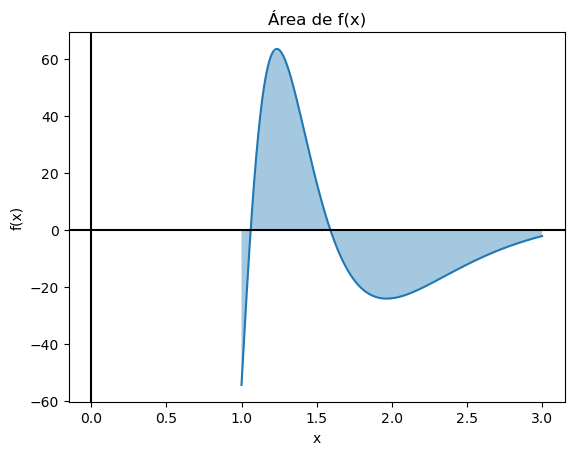

In [29]:
import matplotlib.pyplot as plt #librería para la generación de gráficas

xx=np.linspace(1,3,1000) #genera una reticula o una partición
plt.plot(xx,h(xx)) #dibuja la gráfica de nuestra función ejemplo
plt.xlabel('x') #un pequeño letrero que indica los valores de x
plt.ylabel('f(x)') #un pequeño letrero que indica los valores de f(x)
plt.title('Área de f(x)') #xncabezado de la gráfica
plt.axhline(y=0, color = 'black') #pinta un eje X
plt.axvline(x=0, color = 'black') #pinta un eje Y
a_I=np.linspace(1,3) #es importante esto, funciona como indicador para el área que se quiere sombrear de la integral
plt.fill_between(a_I, h(a_I), 0, alpha=0.4) #colorea el area bajo la curva de f(x) de 1 a 3
